# 🕵️ Fake Job Posting Detector — NLP + Classification Project

**Business problem:** Job scams steal money and personal data from job seekers, often freshers. A job portal can't manually review thousands of new postings a day.
**Goal:** Automatically flag postings that are likely **fraudulent** so a human reviews them before they go live.
**Data:** 17,880 real job ads (the EMSCAD dataset, University of the Aegean). 866 of them are confirmed fakes.

| Step | What we do | Concept from the course |
|---|---|---|
| 1 | Define the problem + the cost of each mistake | [Part 1 – Steps of an ML project](https://youtu.be/1L420xXpDTg?t=1520), [Part 3 – Classification](https://youtu.be/omGvjpmPDoY?t=311) |
| 2 | EDA: imbalance, missing values as signals | [Part 1 – EDA](https://youtu.be/1L420xXpDTg?t=1695) |
| 3 | Remove duplicates, handle missing values | [Part 1 – Data cleaning](https://youtu.be/1L420xXpDTg?t=2025) |
| 4 | Text preprocessing pipeline | [NLP video](https://youtu.be/yiNS_Sh9KDA) – lowercasing, punctuation/emoji/stopword removal |
| 5 | Engineer "missing info" features | [Part 1 – Feature engineering](https://youtu.be/1L420xXpDTg?t=3250) |
| 6 | Bag of Words vs TF-IDF | [NLP video](https://youtu.be/yiNS_Sh9KDA) |
| 7 | Why accuracy lies: confusion matrix, precision, recall, F1 | [Part 3 – Model evaluation](https://youtu.be/omGvjpmPDoY?t=3384) |
| 8 | Logistic Regression, KNN, Naive Bayes, Decision Tree, SVM | [Part 3](https://youtu.be/omGvjpmPDoY?t=512) |
| 9 | Random Forest (bagging), XGBoost (boosting) | [Part 4 – Ensembles](https://youtu.be/UFAHXZW2hU8?t=4449) |
| 10 | Cross-validation, GridSearchCV, RandomizedSearchCV | [Part 4 – Model tuning](https://youtu.be/UFAHXZW2hU8?t=646) |
| 11 | Stacking | [Part 4 – Stacking](https://youtu.be/UFAHXZW2hU8?t=4976) |
| 12 | Decision threshold tuning | [Part 3 – Logistic regression (sigmoid)](https://youtu.be/omGvjpmPDoY?t=512) |
| 13 | Final test + which words give scams away | — |
| 14 | K-Means on text + dimensionality reduction | [Part 4 – K-Means](https://youtu.be/UFAHXZW2hU8?t=9931), [Dimensionality reduction](https://youtu.be/UFAHXZW2hU8?t=12593) |

## 1. Problem definition
- **Type of ML:** supervised **binary classification**. Each posting is labelled `fraudulent = 1` (fake) or `0` (real).
- **Input:** the posting's text (title, company profile, description, requirements, benefits) plus a few yes/no fields (logo? salary?).
- **The two mistakes are not equally bad:**
  - **False negative** (a fake marked real): a job seeker could lose money or ID documents. **Very costly.**
  - **False positive** (a real job flagged): a reviewer spends 30 seconds checking it. **Cheap.**
- So we care most about **recall** (catching fakes) while keeping **precision** reasonable, so reviewers aren't flooded. **F1** balances the two.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

raw = pd.read_csv("data/fake_job_postings.csv")
print(raw.shape)
raw.head(3)

(17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate ...","Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is...",Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 editorial voi...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production Service.90 Seconds is the worlds Cloud Video Production Service enabli...",Organised - Focused - Vibrant - Awesome!Do you have a passion for customer service? Slick typing skills? Maybe Accou...,"What we expect from you:Your key responsibility will be to communicate with the client, 90 Seconds team and freelanc...",What you will get from usThrough being part of the 90 Seconds team you will gain:experience working on projects loca...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,"Valor Services provides Workforce Solutions that meet the needs of companies across the Private Sector, with a speci...","Our client, located in Houston, is actively seeking an experienced Commissioning Machinery Assistant that possesses ...",Implement pre-commissioning and commissioning procedures for rotary equipment.Execute all activities with subcontrac...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0


## 2. Exploratory Data Analysis

fraudulent
0    17014
1      866

Only 4.8% of postings are fake -> a heavily IMBALANCED dataset


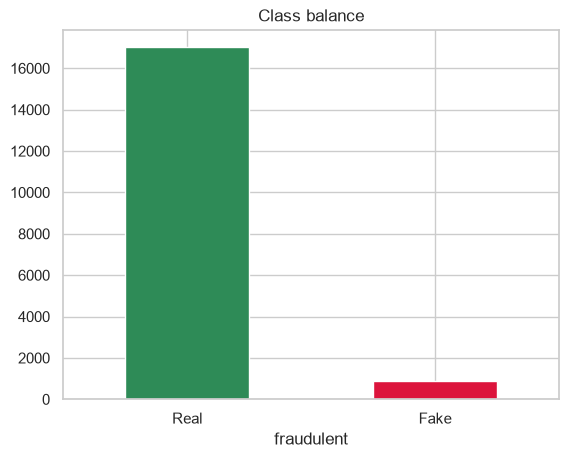

In [2]:
counts = raw["fraudulent"].value_counts()
print(counts.to_string())
print(f"\nOnly {counts[1] / len(raw):.1%} of postings are fake -> a heavily IMBALANCED dataset")
counts.rename({0: "Real", 1: "Fake"}).plot.bar(color=["seagreen", "crimson"], rot=0, title="Class balance")
plt.show()

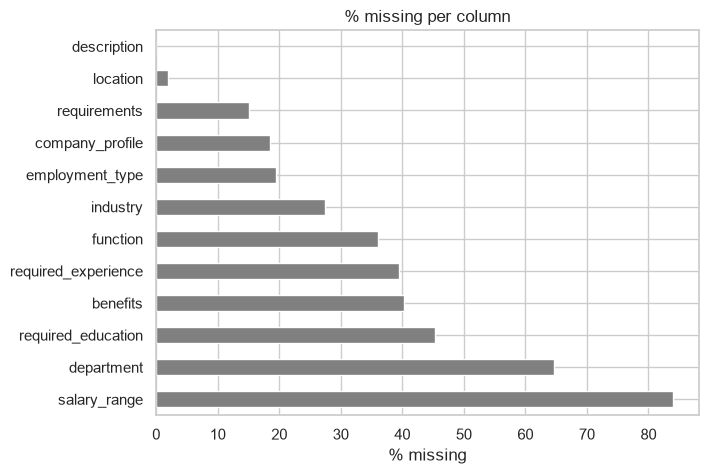

In [3]:
missing = raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].mul(100).plot.barh(figsize=(7, 5), color="grey", title="% missing per column")
plt.xlabel("% missing")
plt.show()

Lots of missing values. But **is "missing" random, or does it tell us something?** Let's compare the fraud rate when a field is filled in vs left empty:

In [4]:
signals = {}
for col in ["company_profile", "salary_range", "requirements", "benefits"]:
    signals[f"{col} missing?"] = raw.groupby(raw[col].isna())["fraudulent"].mean()
for col in ["has_company_logo", "has_questions", "telecommuting"]:
    signals[f"{col}?"] = raw.groupby(raw[col] == 1)["fraudulent"].mean()
signal_df = pd.DataFrame(signals).T.rename(columns={False: "No", True: "Yes"}).mul(100).round(1)
signal_df.columns = [f"fraud % if {c}" for c in signal_df.columns]
signal_df

,fraud % if No,fraud % if Yes
company_profile missing?,1.9,17.7
salary_range missing?,7.8,4.3
requirements missing?,4.7,5.7
benefits missing?,4.7,5.0
has_company_logo?,15.9,2.0
has_questions?,6.8,2.8
telecommuting?,4.7,8.3


**Big insight:** a missing company profile pushes the fraud rate from ~2% to ~18%. No company logo pushes it from ~2% to ~16%. Scammers don't bother describing a company that doesn't exist. **Missing data is a feature here, not just a problem to fill in.**

**Surprise:** *listing* a salary **raises** the fraud rate (7.8% vs 4.3%), because scams advertise attractive pay. Missing requirements or benefits barely matter. EDA stops us from assuming "more missing = more suspicious" for every field.

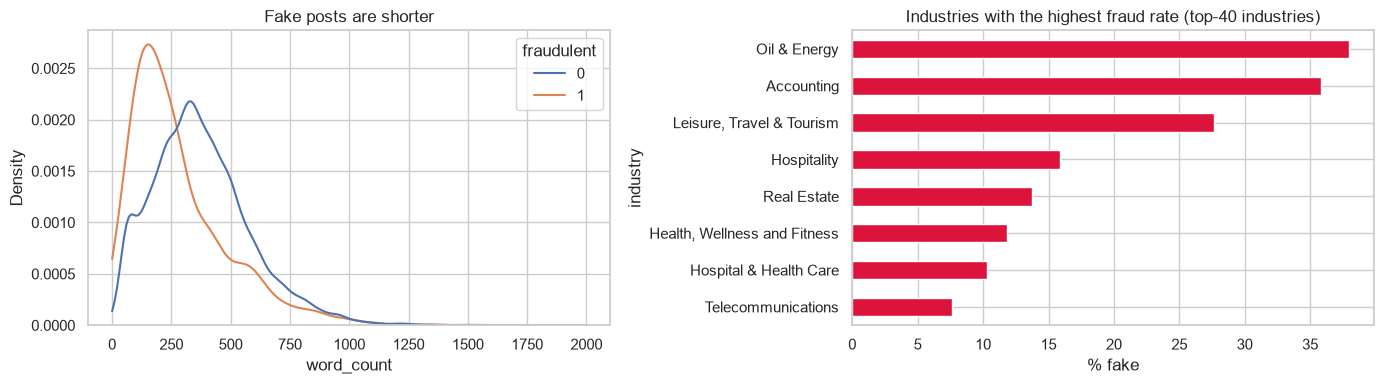

In [5]:
raw["word_count"] = raw[["company_profile", "description", "requirements", "benefits"]].fillna("").agg(" ".join, axis=1).str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(data=raw, x="word_count", hue="fraudulent", common_norm=False, clip=(0, 2000), ax=ax[0])
ax[0].set_title("Fake posts are shorter")
top_ind = raw["industry"].value_counts().head(40).index
ind_rate = raw[raw["industry"].isin(top_ind)].groupby("industry")["fraudulent"].mean().sort_values(ascending=False).head(8) * 100
ind_rate.sort_values().plot.barh(ax=ax[1], color="crimson")
ax[1].set_xlabel("% fake")
ax[1].set_title("Industries with the highest fraud rate (top-40 industries)")
plt.tight_layout()
plt.show()
raw = raw.drop(columns="word_count")

**Insight:** Oil & Energy (~38% fake!), Accounting (~36%) and Leisure/Travel postings are hit hardest. These scams promise high pay for little experience.

## 3. Data cleaning
1. **Duplicates.** The same ad is often re-posted. If one copy lands in train and another in test, the model just "remembers" it and the test score is inflated. This is called **data leakage**, so we drop exact duplicates of the text.
2. **Missing values.** Text fields: fill with an empty string. Yes/no fields: create "has_X" flags (done in feature engineering).

In [6]:
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
before = len(raw)
data = raw.drop_duplicates(subset=text_cols).reset_index(drop=True)
print(f"Removed {before - len(data)} duplicate postings -> {len(data)} remain "
      f"({data['fraudulent'].mean():.1%} fake)")

Removed 1814 duplicate postings -> 16066 remain (4.5% fake)


## 4. Text preprocessing
Computers can't read. We turn messy text into clean tokens, step by step. The code is in [`features.py`](features.py) so the app cleans new postings **the same way**:

| # | Step | Example |
|---|---|---|
| 0 | Split glued words | `"worldwide.Carefully"` → `"worldwide. Carefully"` |
| 1 | Lowercase | `"Data Entry"` → `"data entry"` (same word, same token) |
| 2 | Remove `#URL_…#`, `#EMAIL_…#` placeholders | the dataset anonymised them |
| 3 | Remove HTML tags | `<br>` |
| 4 | Remove emojis / non-English symbols | `"💰💰"` |
| 5 | Remove punctuation and numbers | `"$$$ 5000!!!"` |
| 6 | Remove **stopwords** | "the", "is", "and" appear everywhere and carry no signal |
| 7 | **Stemming** | "earning", "earned", "earns" → `"earn"` |

In [7]:
from features import META_FEATURES, clean_text, make_features

example = "Earn $5000/week 💰 working from HOME!!! No experience needed.Apply at #URL_abc123#"
print("BEFORE:", example)
print("AFTER :", clean_text(example))

BEFORE: Earn $5000/week 💰 working from HOME!!! No experience needed.Apply at #URL_abc123#
AFTER : earn week work home experi need appli


## 5. Feature engineering
Next to the cleaned text we add **8 numeric features** that capture what EDA showed:
`has_company_logo`, `has_questions`, `telecommuting`, `has_company_profile`, `has_salary`, `has_requirements`, `has_benefits`, `log_word_count`.

In [8]:
features = make_features(data)
y = data["fraudulent"].to_numpy()
features[["clean_text"] + META_FEATURES].head()

,clean_text,has_company_logo,has_questions,telecommuting,has_company_profile,has_salary,has_requirements,has_benefits,log_word_count
0,market intern food creat groundbreak award win cook site support connect celebr home cook give everyth need one plac...,1,0,0,1,0,1,0,5.948035
1,custom servic cloud video product second world cloud video product servic second world cloud video product servic en...,1,0,0,1,0,1,1,6.804615
2,commiss machineri assist cma valor servic provid workforc solut meet need compani across privat sector special focu ...,1,0,0,1,0,1,0,5.886104
3,account execut washington dc passion improv qualiti life geographi heart everyth esri geograph inform system gi tech...,1,0,0,1,0,1,1,6.565265
4,bill review manag spot sourc solut llc global human capit manag consult firm headquart miami florida found januari s...,1,1,0,1,0,1,1,6.154858


**Split before fitting anything:** 80% train / 20% test, **stratified** so both sets keep the same ~4.5% fake rate. Without stratifying, a random split could leave the test set with very few fakes.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    features, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} postings ({y_train.mean():.2%} fake) | Test: {len(X_test)} ({y_test.mean():.2%} fake)")

Train: 12852 postings (4.47% fake) | Test: 3214 (4.48% fake)


## 6. Turning words into numbers: Bag of Words vs TF-IDF
**Bag of Words (CountVectorizer):** build a vocabulary of all words, then count how often each one appears in each document. Word order is lost, hence "bag".

**TF-IDF (TfidfVectorizer):** count × *rarity*.
- **TF** (term frequency): how often the word appears *in this document*.
- **IDF** (inverse document frequency): log(total docs / docs containing the word). Words found everywhere ("work", "team") get a **low** weight. Rare, telling words ("wire", "upfront") get a **high** weight.

A toy example:

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

toy = ["work from home earn money", "software engineer work in team", "earn money fast money"]
bow = CountVectorizer().fit(toy)
tfidf = TfidfVectorizer().fit(toy)
print("Bag of Words (counts):")
display(pd.DataFrame(bow.transform(toy).toarray(), columns=bow.get_feature_names_out(), index=["doc1", "doc2", "doc3"]))
print("TF-IDF (weights): 'work' appears in 2 docs -> lower weight than rare words like 'fast'")
display(pd.DataFrame(tfidf.transform(toy).toarray(), columns=tfidf.get_feature_names_out(), index=["doc1", "doc2", "doc3"]).round(2))

Bag of Words (counts):


,earn,engineer,fast,from,home,in,money,software,team,work
doc1,1,0,0,1,1,0,1,0,0,1
doc2,0,1,0,0,0,1,0,1,1,1
doc3,1,0,1,0,0,0,2,0,0,0


TF-IDF (weights): 'work' appears in 2 docs -> lower weight than rare words like 'fast'


,earn,engineer,fast,from,home,in,money,software,team,work
doc1,0.39,0.00,0.00,0.52,0.52,0.00,0.39,0.00,0.00,0.39
doc2,0.00,0.47,0.00,0.00,0.00,0.47,0.00,0.47,0.47,0.36
doc3,0.39,0.00,0.51,0.00,0.00,0.00,0.77,0.00,0.00,0.00


We also use **n-grams** `(1, 2)`: single words *and* word pairs. "no experience" means something very different from "experience" alone.

Next, we build both representations on the training data and compare them with **5-fold stratified cross-validation**. To keep the comparison fast, the vectorizers are fitted once on the full training set. The tuned model in Section 10 refits everything *inside* each fold with a `Pipeline`, which is the leak-free way.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler


def make_preprocessor(vectorizer):
    """Text -> BoW/TF-IDF columns, meta features -> scaled to 0..1, glued side by side."""
    return ColumnTransformer([("text", vectorizer, "clean_text"), ("meta", MinMaxScaler(), META_FEATURES)])


vec_params = dict(max_features=20000, ngram_range=(1, 2), min_df=2)
bow_prep = make_preprocessor(CountVectorizer(**vec_params)).fit(X_train)
tfidf_prep = make_preprocessor(TfidfVectorizer(**vec_params, sublinear_tf=True)).fit(X_train)
Xtr_bow, Xtr_tfidf = bow_prep.transform(X_train), tfidf_prep.transform(X_train)
Xte_tfidf = tfidf_prep.transform(X_test)
feature_names = tfidf_prep.get_feature_names_out()
print("Matrix shape:", Xtr_tfidf.shape, f"| {Xtr_tfidf.nnz / np.prod(Xtr_tfidf.shape):.2%} non-zero (sparse!)")

Matrix shape: (12852, 20008) | 1.28% non-zero (sparse!)


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1"]


def cv_scores(model, X):
    s = cross_validate(model, X, y_train, cv=skf, scoring=SCORING, n_jobs=-1)
    return {m: s[f"test_{m}"].mean() for m in SCORING}


rows = {}
for rep_name, X_rep in [("Bag of Words", Xtr_bow), ("TF-IDF", Xtr_tfidf)]:
    rows[f"Naive Bayes + {rep_name}"] = cv_scores(MultinomialNB(), X_rep)
    rows[f"Logistic Regression + {rep_name}"] = cv_scores(LogisticRegression(max_iter=3000, C=10), X_rep)
pd.DataFrame(rows).T.round(3)

,accuracy,precision,recall,f1
Naive Bayes + Bag of Words,0.923,0.352,0.850,0.498
Logistic Regression + Bag of Words,0.981,0.846,0.704,0.768
Naive Bayes + TF-IDF,0.958,0.687,0.105,0.181
Logistic Regression + TF-IDF,0.983,0.961,0.648,0.774


**Reading the table:**
- **Logistic Regression does slightly better with TF-IDF**, with much higher precision. Down-weighting common words helps it focus on telling ones.
- **Naive Bayes behaves very differently on the two.** With BoW it catches most fakes but raises many false alarms. With TF-IDF it barely flags anything at the default 0.5 cut-off, because Multinomial NB is built for *counts*. Same algorithm, different input, very different behaviour.
- From here on we use **TF-IDF**.

## 7. Why accuracy lies on imbalanced data
A "model" that **always says real** gets ~95.5% accuracy and catches **zero** scams:

In [13]:
from sklearn.dummy import DummyClassifier

pd.Series(cv_scores(DummyClassifier(strategy="most_frequent"), Xtr_tfidf)).round(3).to_frame("Always predict 'real'")

,Always predict 'real'
accuracy,0.955
precision,0.000
recall,0.000
f1,0.000


The **confusion matrix** shows all four outcomes:

| | Predicted real | Predicted fake |
|---|---|---|
| **Actually real** | True Negative ✅ | False Positive (annoying) |
| **Actually fake** | False Negative ❌ (dangerous) | True Positive ✅ |

- **Precision** = TP / (TP + FP): *of the posts we flagged, how many were really fake?*
- **Recall** = TP / (TP + FN): *of all the fakes, how many did we catch?*
- **F1** = harmonic mean of the two. It's high only when **both** are high.

## 8. Five classic classifiers
| Model | Idea in one line |
|---|---|
| **Logistic Regression** | a weighted sum of word scores → sigmoid → probability of fake |
| **KNN** | look at the 5 most similar postings (cosine similarity) and take a majority vote |
| **Naive Bayes** | P(fake given these words) using Bayes' theorem, assuming words are independent ("naive") |
| **Decision Tree** | a flowchart of yes/no questions ("contains 'wire transfer'?") |
| **Linear SVM** | the boundary with the **widest margin** between real and fake |

**Handling imbalance:** `class_weight="balanced"` makes a mistake on a rare fake cost ~21× more than a mistake on a real post. Without it, models learn to ignore the minority class.

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

classic_models = {
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "KNN (k=5, cosine)": KNeighborsClassifier(n_neighbors=5, metric="cosine"),
    "Naive Bayes (BoW)": MultinomialNB(),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(class_weight="balanced"),
}
results = {}
for name, model in classic_models.items():
    X_rep = Xtr_bow if "BoW" in name else Xtr_tfidf
    results[name] = cv_scores(model, X_rep)
pd.DataFrame(results).T.sort_values("f1", ascending=False).round(3)

,accuracy,precision,recall,f1
Linear SVM,0.986,0.870,0.800,0.833
"KNN (k=5, cosine)",0.978,0.816,0.669,0.735
Logistic Regression,0.957,0.514,0.906,0.655
Decision Tree,0.963,0.578,0.678,0.622
Naive Bayes (BoW),0.923,0.352,0.850,0.498


## 9. Ensembles: bagging and boosting
- **Random Forest (bagging):** hundreds of decision trees, each on a random sample of rows and words, then a vote. A single tree overfits. The forest averages out the noise.
- **XGBoost (boosting):** trees are built *in sequence*, and each one fixes the errors of the ones before it. `scale_pos_weight` is XGBoost's version of class weighting.
  - For speed we first keep the **3,000 most informative columns** using the chi-square test. That's **feature selection**: chi² measures how strongly a word's presence depends on the class.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {pos_weight:.1f}  (real : fake ratio)")

ensemble_models = {
    "Random Forest (bagging)": RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost (boosting)": Pipeline([
        ("chi2", SelectKBest(chi2, k=3000)),
        ("xgb", XGBClassifier(n_estimators=300, learning_rate=0.2, max_depth=4, scale_pos_weight=pos_weight,
                              tree_method="hist", n_jobs=2, random_state=RANDOM_STATE)),
    ]),
}
for name, model in ensemble_models.items():
    results[name] = cv_scores(model, Xtr_tfidf)
pd.DataFrame(results).T.sort_values("f1", ascending=False).round(3)

scale_pos_weight = 21.4  (real : fake ratio)


,accuracy,precision,recall,f1
Linear SVM,0.986,0.870,0.800,0.833
XGBoost (boosting),0.980,0.792,0.754,0.772
"KNN (k=5, cosine)",0.978,0.816,0.669,0.735
Logistic Regression,0.957,0.514,0.906,0.655
Random Forest (bagging),0.976,0.974,0.481,0.643
Decision Tree,0.963,0.578,0.678,0.622
Naive Bayes (BoW),0.923,0.352,0.850,0.498


**Note on Random Forest:** near-perfect precision but low recall. When it says "fake" it's right, but it misses about half the fakes. Each tree sees only a few of the thousands of rare scam words, so the majority vote stays cautious. Section 12 shows how moving the **decision threshold** trades precision for recall.

## 10. Hyperparameter tuning
### GridSearchCV on the full pipeline
This time the TF-IDF vectorizer sits **inside** the pipeline. In every CV fold, the vocabulary and IDF weights are learned from that fold's training part only, so there's **zero leakage**. We tune the text settings *and* the model together. (3 folds here to save time: 16 combos × 3 = 48 fits.)

In [16]:
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("prep", make_preprocessor(TfidfVectorizer(min_df=2, max_features=20000, sublinear_tf=True))),
    ("model", LinearSVC(class_weight="balanced")),
])
svm_grid = GridSearchCV(
    svm_pipeline,
    param_grid={
        "prep__text__ngram_range": [(1, 1), (1, 2)],
        "model__C": [0.1, 0.3, 1, 3],
        "model__class_weight": [None, "balanced"],
    },
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1", n_jobs=-1,
)
svm_grid.fit(X_train, y_train)
print("Best params:", svm_grid.best_params_)
print(f"Best CV F1 : {svm_grid.best_score_:.3f}")
pd.DataFrame(svm_grid.cv_results_)[["param_prep__text__ngram_range", "param_model__C", "param_model__class_weight",
                                    "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(6).round(3)

Best params: {'model__C': 1, 'model__class_weight': 'balanced', 'prep__text__ngram_range': (1, 2)}
Best CV F1 : 0.824


,param_prep__text__ngram_range,param_model__C,param_model__class_weight,mean_test_score
11,"(1, 2)",1.0,balanced,0.824
15,"(1, 2)",3.0,balanced,0.821
13,"(1, 2)",3.0,NaN,0.808
12,"(1, 1)",3.0,NaN,0.794
14,"(1, 1)",3.0,balanced,0.794
7,"(1, 2)",0.3,balanced,0.786


**Notice:** the leak-free pipeline score is a little *lower* than the quick comparison table above. Part of that is 3 vs 5 folds. Part is the small optimism you get when the vectorizer has already seen the validation folds. Leak-free numbers are the honest ones.

### RandomizedSearchCV for Logistic Regression
`C` is the inverse of regularisation strength: small C = simpler model, big C = fits the training data harder. Instead of a fixed grid, we sample 25 random values on a log scale.

In [17]:
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV

lr_search = RandomizedSearchCV(
    LogisticRegression(max_iter=5000),
    param_distributions={"C": loguniform(0.1, 100), "class_weight": [None, "balanced"]},
    n_iter=25, cv=skf, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1,
)
lr_search.fit(Xtr_tfidf, y_train)
print("Best params:", {k: round(v, 2) if isinstance(v, float) else v for k, v in lr_search.best_params_.items()})
print(f"Best CV F1 : {lr_search.best_score_:.3f}")
results["Logistic Regression (RandomSearch-tuned)"] = cv_scores(lr_search.best_estimator_, Xtr_tfidf)

Best params: {'C': np.float64(31.43), 'class_weight': 'balanced'}
Best CV F1 : 0.827


## 11. Stacking
Three different "experts" (Logistic Regression, Linear SVM, Naive Bayes) each give their opinion. A meta Logistic Regression learns **how much to trust each one**. This helps when they make different mistakes.

In [18]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[
        ("lr", lr_search.best_estimator_),
        ("svm", LinearSVC(C=svm_grid.best_params_["model__C"], class_weight=svm_grid.best_params_["model__class_weight"])),
        ("nb", MultinomialNB(alpha=0.1)),
    ],
    final_estimator=LogisticRegression(),
    cv=5, n_jobs=-1,
)
results["Stacking (LR + SVM + NB)"] = cv_scores(stack, Xtr_tfidf)
results["Linear SVM (GridSearch-tuned)"] = {"f1": svm_grid.best_score_}
leaderboard = pd.DataFrame(results).T.sort_values("f1", ascending=False)
leaderboard.round(3)

,accuracy,precision,recall,f1
Stacking (LR + SVM + NB),0.986,0.910,0.770,0.834
Linear SVM,0.986,0.870,0.800,0.833
Logistic Regression (RandomSearch-tuned),0.985,0.834,0.821,0.827
Linear SVM (GridSearch-tuned),NaN,NaN,NaN,0.824
XGBoost (boosting),0.980,0.792,0.754,0.772
"KNN (k=5, cosine)",0.978,0.816,0.669,0.735
Logistic Regression,0.957,0.514,0.906,0.655
Random Forest (bagging),0.976,0.974,0.481,0.643
Decision Tree,0.963,0.578,0.678,0.622
Naive Bayes (BoW),0.923,0.352,0.850,0.498


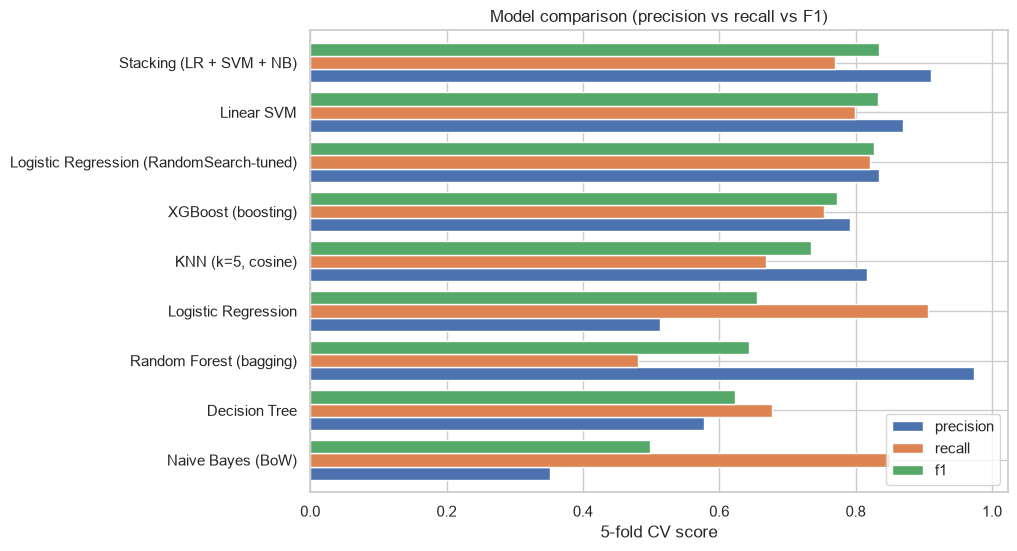

In [19]:
plot_df = leaderboard.drop(index="Linear SVM (GridSearch-tuned)")[["precision", "recall", "f1"]].sort_values("f1")
plot_df.plot.barh(figsize=(9, 6), width=0.8)
plt.xlabel("5-fold CV score")
plt.title("Model comparison (precision vs recall vs F1)")
plt.legend(loc="lower right")
plt.show()

## 12. Choosing the decision threshold
Linear models output a **score** (for Logistic Regression, the sigmoid turns it into a probability). By default we say "fake" when probability > 0.5, but **0.5 is just a convention**. Lowering the threshold catches more fakes (recall ↑) but flags more real posts (precision ↓).

We choose the threshold on **out-of-fold predictions from the training set**, never on the test set. Using the test set would be cheating.

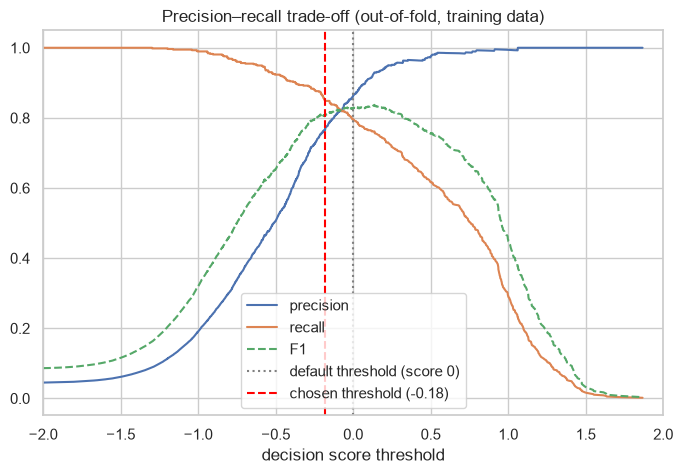

Default : precision 0.86, recall 0.80
Chosen  : precision 0.77, recall 0.85  (rule: recall ≥ 0.85, then max precision)


In [20]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

final_model = svm_grid.best_estimator_
oof_scores = cross_val_predict(final_model, X_train, y_train, cv=skf, method="decision_function", n_jobs=-1)
prec, rec, thr = precision_recall_curve(y_train, oof_scores)
f1 = 2 * prec * rec / (prec + rec + 1e-12)

# business rule: catch at least 85% of fakes, and among those thresholds pick the most precise one
ok = rec[:-1] >= 0.85
best_i = np.argmax(np.where(ok, prec[:-1], -1))
threshold = thr[best_i]
default_i = np.argmin(np.abs(thr))

plt.figure(figsize=(8, 5))
plt.plot(thr, prec[:-1], label="precision")
plt.plot(thr, rec[:-1], label="recall")
plt.plot(thr, f1[:-1], label="F1", ls="--")
plt.axvline(0, color="grey", ls=":", label="default threshold (score 0)")
plt.axvline(threshold, color="red", ls="--", label=f"chosen threshold ({threshold:.2f})")
plt.xlim(-2, 2)
plt.xlabel("decision score threshold")
plt.legend()
plt.title("Precision–recall trade-off (out-of-fold, training data)")
plt.show()
print(f"Default : precision {prec[default_i]:.2f}, recall {rec[default_i]:.2f}")
print(f"Chosen  : precision {prec[best_i]:.2f}, recall {rec[best_i]:.2f}  (rule: recall ≥ 0.85, then max precision)")

## 13. Final evaluation on the untouched test set
We fit the tuned Linear SVM pipeline on the full training set and score the 20% test set **once**, at both the default and the chosen threshold.

Why Linear SVM? It is top or near-top on F1, trains in seconds, and is **explainable**: every word has a weight we can show to a reviewer.

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score, precision_score, recall_score

final_model.fit(X_train, y_train)
test_scores = final_model.decision_function(X_test)
test_rows = {}
for label, t in [("default threshold", 0.0), (f"chosen threshold ({threshold:.2f})", threshold)]:
    pred = (test_scores >= t).astype(int)
    test_rows[label] = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
                        "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred)}
test_report = pd.DataFrame(test_rows).T.round(3)
test_report

,accuracy,precision,recall,f1
default threshold,0.984,0.854,0.771,0.810
chosen threshold (-0.18),0.980,0.752,0.840,0.793


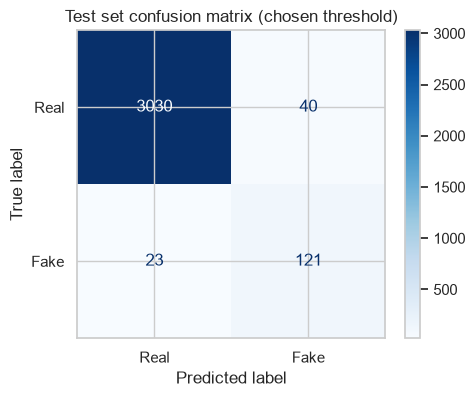

              precision    recall  f1-score   support

        Real      0.992     0.987     0.990      3070
        Fake      0.752     0.840     0.793       144

    accuracy                          0.980      3214
   macro avg      0.872     0.914     0.892      3214
weighted avg      0.982     0.980     0.981      3214



In [22]:
test_pred = (test_scores >= threshold).astype(int)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Real", "Fake"], cmap="Blues", ax=ax)
ax.set_title("Test set confusion matrix (chosen threshold)")
plt.show()
print(classification_report(y_test, test_pred, target_names=["Real", "Fake"], digits=3))

**Reading the result:** the chosen threshold gives up a little F1 and precision to catch noticeably more fakes. That's exactly the business rule: a missed scam costs far more than a 30-second review. The default-threshold row shows the alternative if reviewers' time were the bigger concern.

### Which words give scams away?
A linear model's weights *are* the explanation. A positive weight pushes towards "fake", a negative one towards "real".

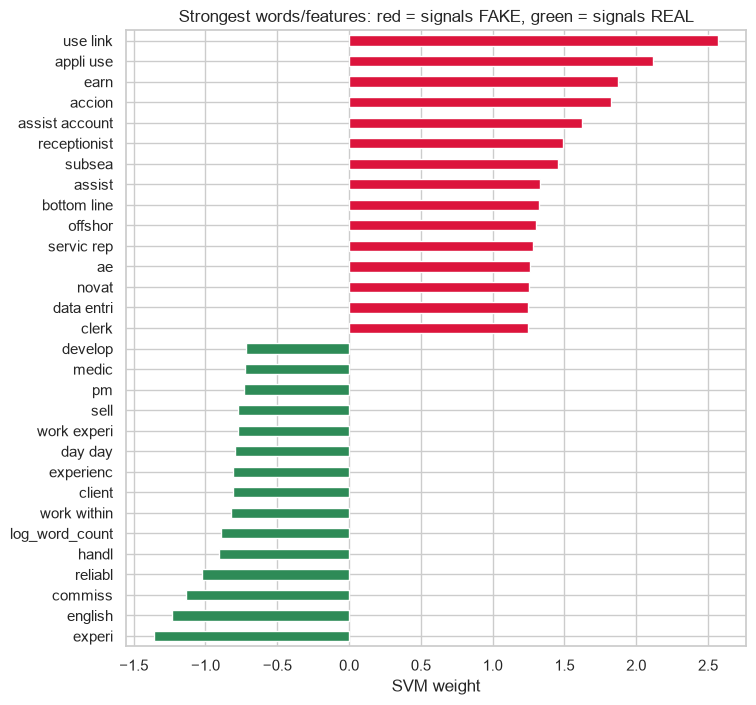

Meta-feature weights:
 log_word_count        -0.89
has_company_logo      -0.35
has_company_profile   -0.23
has_questions         -0.06
has_benefits          -0.01
telecommuting          0.01
has_requirements       0.10
has_salary             0.10


In [23]:
svm = final_model.named_steps["model"]
names = final_model.named_steps["prep"].get_feature_names_out()
weights = pd.Series(svm.coef_[0], index=[n.split("__", 1)[1] for n in names])
top = pd.concat([weights.nlargest(15), weights.nsmallest(15)]).sort_values()
plt.figure(figsize=(8, 8))
top.plot.barh(color=["seagreen" if w < 0 else "crimson" for w in top])
plt.title("Strongest words/features: red = signals FAKE, green = signals REAL")
plt.xlabel("SVM weight")
plt.show()
print("Meta-feature weights:\n", weights[META_FEATURES].round(2).sort_values().to_string())

**How to read it:**
- **Fake signals:** pay promises ("earn"), off-platform instructions ("apply using link"), low-skill admin roles ("data entry", "clerk", "receptionist", "assistant") and offshore/subsea oil & gas jobs.
- **Real signals:** concrete requirements ("experience", "English", "reliable"), client/sales/commission roles, development work, and **longer** postings (`log_word_count`).
- Having a company logo and profile pushes towards real, which matches the EDA.

## 14. Unsupervised: what kinds of jobs are there, and where do scams hide?
No labels are used here. **K-Means** groups postings with similar wording, and afterwards we check each group's fraud rate.

1. **Dimensionality reduction first.** 20,000 TF-IDF columns are too many: distances get noisy in so many dimensions (the *curse of dimensionality*). **TruncatedSVD** is PCA for sparse text matrices (also called LSA). We compress to 100 "topic" dimensions.
2. **K-Means** with K chosen by elbow + silhouette.

20,000 columns -> 100 components, keeping 26% of the variance


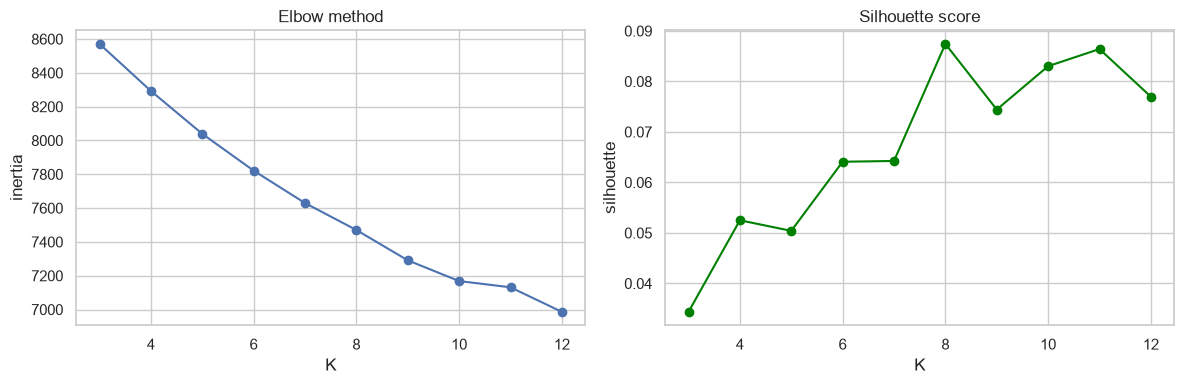

In [24]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import Normalizer

text_only = Xtr_tfidf[:, : len(tfidf_prep.named_transformers_["text"].vocabulary_)]
svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
Z = Normalizer().fit_transform(svd.fit_transform(text_only))
print(f"20,000 columns -> 100 components, keeping {svd.explained_variance_ratio_.sum():.0%} of the variance")

ks = list(range(3, 13))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_, sample_size=4000, random_state=RANDOM_STATE))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-")
ax[0].set(title="Elbow method", xlabel="K", ylabel="inertia")
ax[1].plot(ks, sil, "o-", color="green")
ax[1].set(title="Silhouette score", xlabel="K", ylabel="silhouette")
plt.tight_layout()
plt.show()

In [25]:
K = ks[int(np.argmax(sil))]
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
vocab = tfidf_prep.named_transformers_["text"].get_feature_names_out()
centroid_words = svd.inverse_transform(kmeans.cluster_centers_)
clusters = pd.DataFrame({
    "postings": pd.Series(kmeans.labels_).value_counts().sort_index(),
    "fraud %": pd.Series(y_train).groupby(kmeans.labels_).mean().mul(100).round(1),
    "top words": [", ".join(vocab[i] for i in centroid_words[c].argsort()[::-1][:8]) for c in range(K)],
}).sort_values("fraud %", ascending=False)
print(f"K = {K} (highest silhouette)")
clusters

K = 8 (highest silhouette)


,postings,fraud %,top words
1,2327,13.6,"work, must, servic, requir, posit, experi, assist, custom"
3,1637,5.1,"develop, experi, system, softwar, engin, project, manag, design"
0,3149,3.9,"work, servic, experi, compani, team, manag, provid, develop"
4,2503,1.2,"market, manag, sale, work, media, team, busi, social"
2,2003,0.9,"develop, design, web, work, experi, team, mobil, user"
5,429,0.0,"document commun, increas product, busi process, document, mail, increas, enterpris, custom"
6,374,0.0,"websit, job, manufactur, mani medium, larg us, posit mani, us compani, time perman"
7,430,0.0,"apprenticeship, wish, cours, year old, recruit, shall, old, apprenticeship avail"


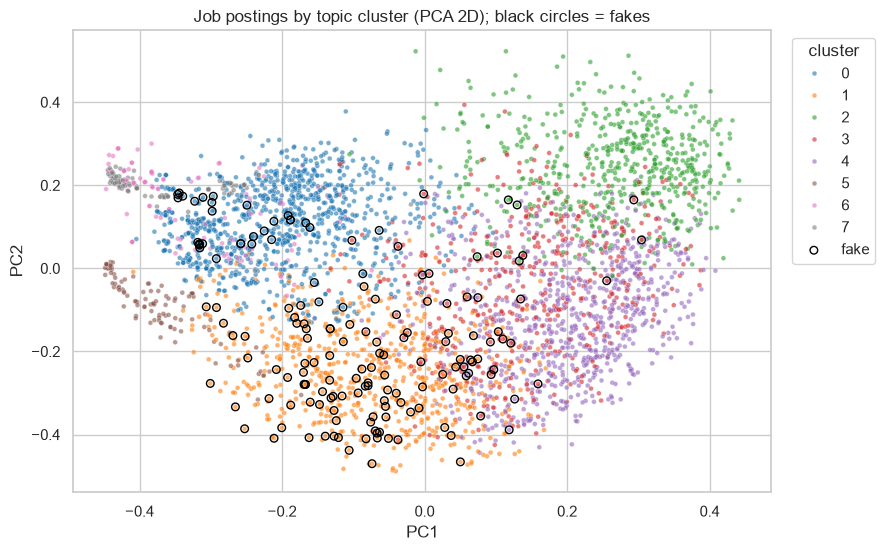

In [26]:
from sklearn.decomposition import PCA

Z2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z)
plt.figure(figsize=(9, 6))
sample = np.random.RandomState(RANDOM_STATE).choice(len(Z2), 4000, replace=False)
sns.scatterplot(x=Z2[sample, 0], y=Z2[sample, 1], hue=kmeans.labels_[sample], palette="tab10", s=12, alpha=0.6, legend="full")
fake = sample[y_train[sample] == 1]
plt.scatter(Z2[fake, 0], Z2[fake, 1], facecolors="none", edgecolors="black", s=30, label="fake")
plt.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("Job postings by topic cluster (PCA 2D); black circles = fakes")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

**Insight:** fakes are **not spread evenly**. They concentrate in the cluster of generic customer-service/admin postings ("must", "assist", "custom…"), while web/software roles are almost scam-free. A portal could apply **stricter review rules** to the high-risk cluster.

## 15. Save the model for the app

In [27]:
import joblib

final_model.fit(features, y)   # refit on ALL data now that evaluation is done
joblib.dump({
    "model": final_model,
    "threshold": float(threshold),
    "test_metrics": test_report.iloc[1].to_dict(),
    "meta_features": META_FEATURES,
}, "model.joblib")
print("Saved model.joblib")

Saved model.joblib


## 16. Summary
- **EDA** showed the data is **95.5% real**, so accuracy is meaningless. Missing company info is a strong scam signal, which became 8 engineered features.
- **Text pipeline:** cleaning → stopwords → stemming → **TF-IDF with word pairs** (TF-IDF beat Bag of Words for the linear models).
- Compared **7 algorithms + stacking** with stratified 5-fold CV. The **Linear SVM**, tuned with GridSearchCV inside a leak-free pipeline, gave the best balance of F1, speed and explainability.
- **Threshold tuning** on out-of-fold predictions turns the model into a business tool: "catch ≥ 85% of scams" with the fewest false alarms.
- **K-Means on SVD-reduced text** shows where scams cluster, which helps set review priorities.

**What I'd do next:** add the employment type / industry / location as features, try sentence embeddings (BERT) for meaning beyond keywords, and retrain regularly as scammers change their wording.